# 02 · Radiografía territorial, demográfica y sectorial de la informalidad en el Ecuador

Mostramos la serie 2018–2025 **publicada por el INEC** (no recalculada; no hay año 2020) y desagregamos la ENEMDU 2025 por provincia, área, sexo, edad, autoidentificación étnica, nivel educativo y rama CIIU Rev. 4, con pruebas de diferencia de dominios que incorporan la covarianza intra-UPM.

In [1]:
import json
import pandas as pd
from empleo_enemdu.config import DIR_PROCESADOS, DIR_REPORTS, DIR_TABLAS

df_serie = pd.read_csv(DIR_PROCESADOS / "serie_historica_2018_2025.csv")
piv = df_serie.loc[df_serie["dominio"] == "Total"].pivot_table(
    index="anio", columns="indicador", values="valor_pct"
)[["Empleo Adecuado/Pleno", "Subempleo", "Otro Empleo no pleno", "Empleo no Remunerado", "Desempleo", "Sector informal"]]
piv.reset_index()

indicador,anio,Empleo Adecuado/Pleno,Subempleo,Otro Empleo no pleno,Empleo no Remunerado,Desempleo,Sector informal
0,2018,40.2,17.8,26.8,10.9,3.9,46.8
1,2019,38.3,18.2,27.4,11.5,4.2,47.3
2,2021,32.5,23.2,27.2,11.1,5.2,49.5
3,2022,34.4,22.2,28.8,9.9,4.4,50.6
4,2023,36.3,19.6,30.2,9.9,3.8,52.5
5,2024,35.9,21.0,29.8,9.5,3.7,52.4
6,2025,37.1,19.4,30.8,8.8,3.6,51.5


## 1. Disparidad provincial: las 24 provincias ordenadas por tasa de informalidad

La tabla se ordena de menor a mayor informalidad; la celda imprime los extremos.

In [2]:
df_prov = pd.read_csv(DIR_TABLAS / "indicadores_provincias_2025.csv").sort_values("informalidad_pct")
extremos = pd.concat([df_prov.head(2), df_prov.tail(3)])
for _, f in extremos.iterrows():
    print(f"{f['provincia']}: informalidad {f['informalidad_pct']:.2f}% (EE {f['informalidad_ee_pct']:.2f})")
df_prov[
    [
        "provincia",
        "region_natural",
        "informalidad_pct",
        "informalidad_ee_pct",
        "empleo_adecuado_pct",
        "subempleo_pct",
        "ingreso_laboral_medio_usd",
    ]
]

Galápagos: informalidad 16.21% (EE 1.81)
Pichincha: informalidad 28.43% (EE 1.04)
Bolívar: informalidad 77.20% (EE 2.41)
Napo: informalidad 81.54% (EE 2.47)
Morona Santiago: informalidad 87.35% (EE 3.32)


,provincia,region_natural,informalidad_pct,informalidad_ee_pct,empleo_adecuado_pct,subempleo_pct,ingreso_laboral_medio_usd
0,Galápagos,Insular,16.21,1.81,59.55,6.77,1244.66
1,Pichincha,Sierra,28.43,1.04,53.03,13.01,651.72
3,El Oro,Costa,43.31,2.42,42.59,20.52,525.93
2,Azuay,Sierra,47.21,2.63,44.87,10.00,554.48
6,Los Ríos,Costa,51.41,2.78,32.53,28.36,420.61
4,Guayas,Costa,51.94,2.16,41.34,22.92,470.50
10,Tungurahua,Sierra,52.01,1.93,30.54,19.45,503.32
12,Imbabura,Sierra,54.21,2.65,29.31,18.59,442.07
5,Santo Domingo,Sierra,54.60,2.77,39.36,18.80,496.58
8,Cañar,Sierra,56.40,2.62,31.66,13.76,453.18


## 2. Brechas por autoidentificación étnica, sexo, edad y nivel educativo

Incluye el **desempleo juvenil (15 a 24 años)**, que se imprime junto a la tasa nacional.

In [3]:
df_sub = pd.read_csv(DIR_TABLAS / "indicadores_subgrupos_2025.csv")
jov = df_sub.set_index(["dimension", "categoria"]).loc[("Grupo de edad", "15 a 24 años")]
print(f"Desempleo juvenil 15-24: {jov['desempleo_pct']:.2f}% (n = {int(jov['n_muestral_pea']):,} jóvenes en la PEA)")
df_sub[
    [
        "dimension",
        "categoria",
        "empleo_adecuado_pct",
        "informalidad_pct",
        "subempleo_pct",
        "desempleo_pct",
        "ingreso_medio_usd",
    ]
]

Desempleo juvenil 15-24: 9.07% (n = 22,654 jóvenes en la PEA)


,dimension,categoria,empleo_adecuado_pct,informalidad_pct,subempleo_pct,desempleo_pct,ingreso_medio_usd
0,Sexo,Hombre,42.43,52.23,20.74,2.85,526.89
1,Sexo,Mujer,29.96,50.47,17.62,4.55,455.02
2,Área,Rural,21.93,71.53,19.82,1.92,374.85
3,Área,Urbana,45.31,40.41,19.20,4.46,554.02
4,Grupo de edad,15 a 24 años,21.76,55.54,23.58,9.07,357.02
5,Grupo de edad,25 a 34 años,44.28,39.82,21.13,5.07,514.29
6,Grupo de edad,35 a 44 años,46.67,44.15,19.07,2.52,577.17
7,Grupo de edad,45 a 64 años,38.73,55.32,18.73,1.35,528.10
8,Grupo de edad,65 años y más,13.75,80.19,10.75,0.72,303.82
9,Autoidentificación étnica,Afroecuatoriano,34.21,51.74,24.80,7.98,429.12


## 3. Ramas de actividad económica (CIIU Rev. 4) y pruebas de contraste con covarianza intra-UPM

Al comparar hombres y mujeres o grupos que cohabitan el mismo hogar y sector censal (`upm`), la covarianza muestral $\text{Cov}(\hat{R}_A, \hat{R}_B)$ no es nula. Nuestro método `prueba_diferencia_dominios` evalúa el contraste exacto sobre los totales linealizados por UPM.

In [4]:
res = json.loads((DIR_REPORTS / "resultados.json").read_text(encoding="utf-8"))
pd.DataFrame(res["contrastes_hipotesis"])

,contraste,grupo_a,grupo_b,tasa_a_pct,tasa_b_pct,diferencia_pp,ee_complejo_pp,ee_independiente_pp,estadistico_t,p_valor,ic95_inf_pp,ic95_sup_pp
0,Empleo adecuado: Hombre vs Mujer (PEA),Hombre,Mujer,42.43,29.96,12.47,0.80,1.01,15.68,1.543769e-54,10.91,14.03
1,Empleo adecuado: Urbano vs Rural (PEA),Urbano,Rural,45.31,21.93,23.39,1.18,1.18,19.86,1.286084e-85,21.08,25.69
2,Sector informal: Rural vs Urbano (Ocupados),Rural,Urbano,71.53,40.41,31.12,1.63,1.63,19.05,4.217689e-79,27.92,34.32
3,Sector informal: Mujer vs Hombre (Ocupados),Mujer,Hombre,50.47,52.23,-1.76,1.11,1.35,-1.58,1.136588e-01,-3.95,0.42


## 4. Figuras clave: serie oficial, provincias, subgrupos y ramas

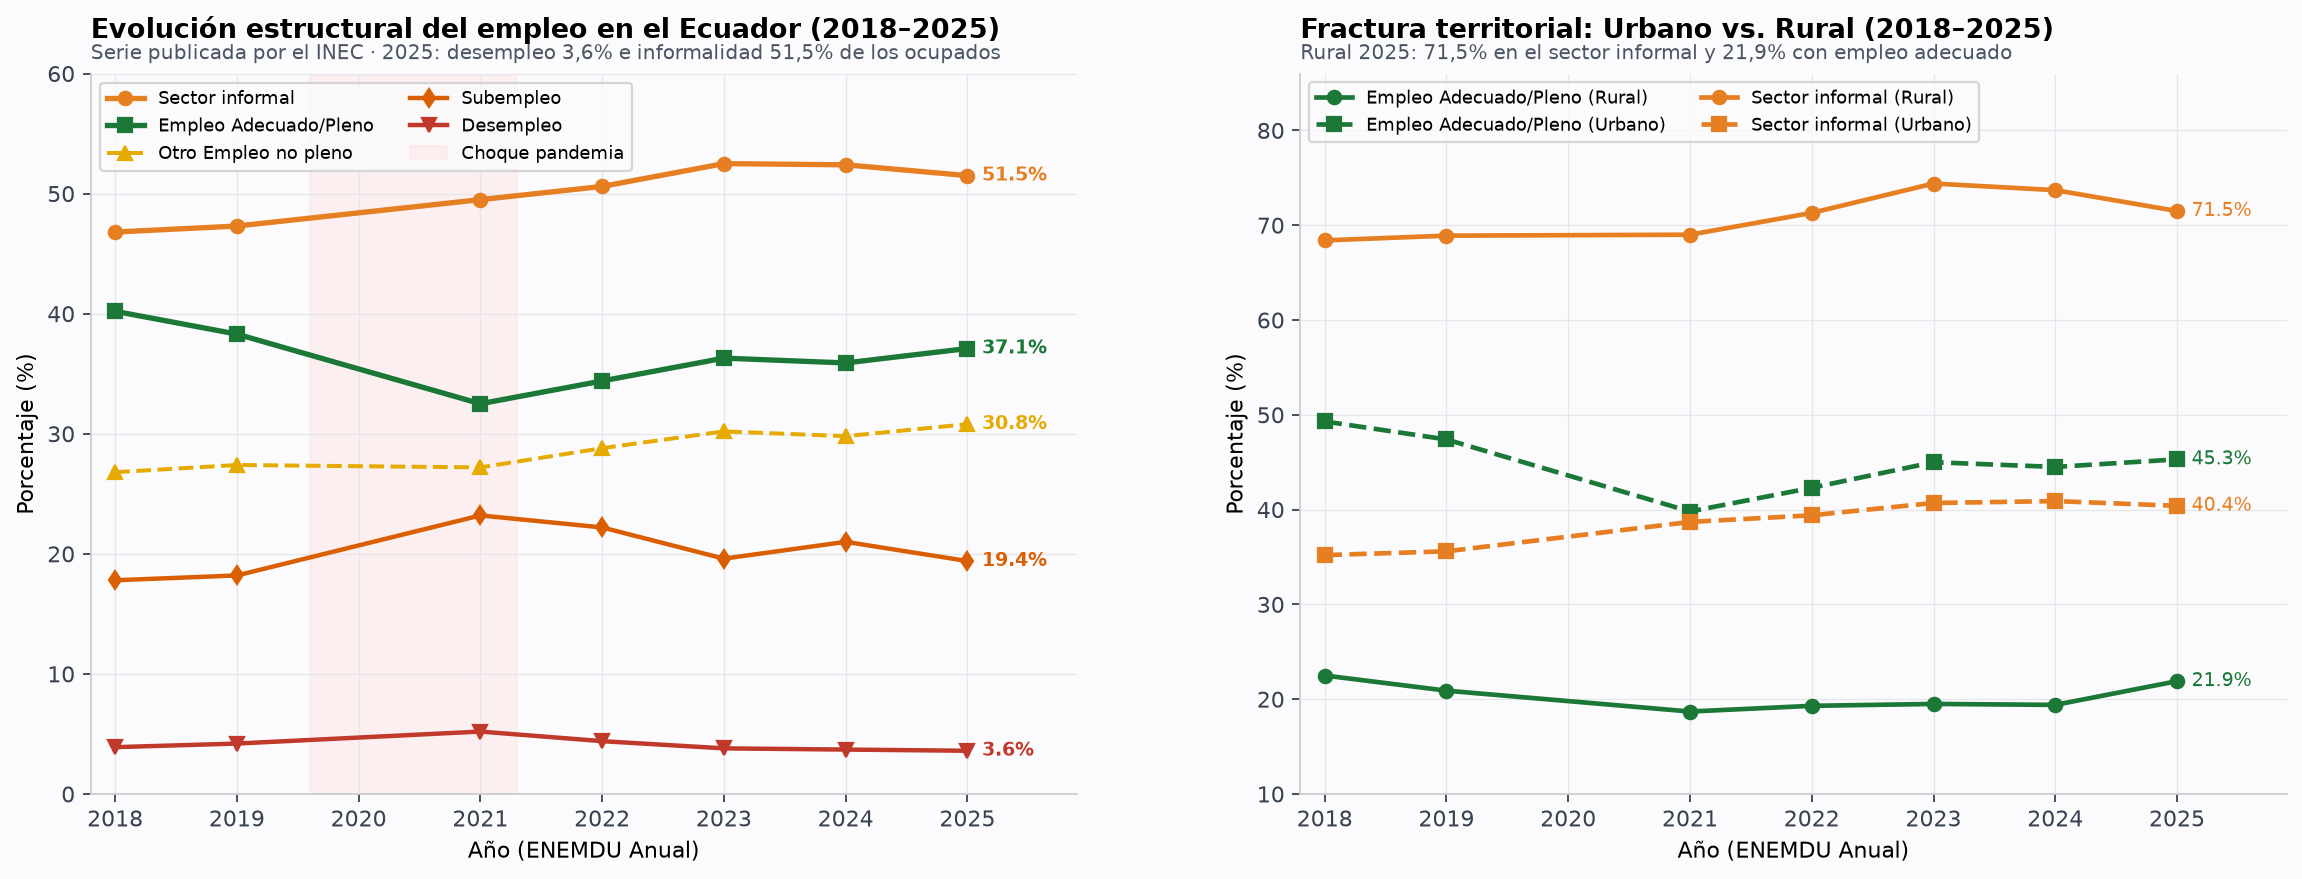

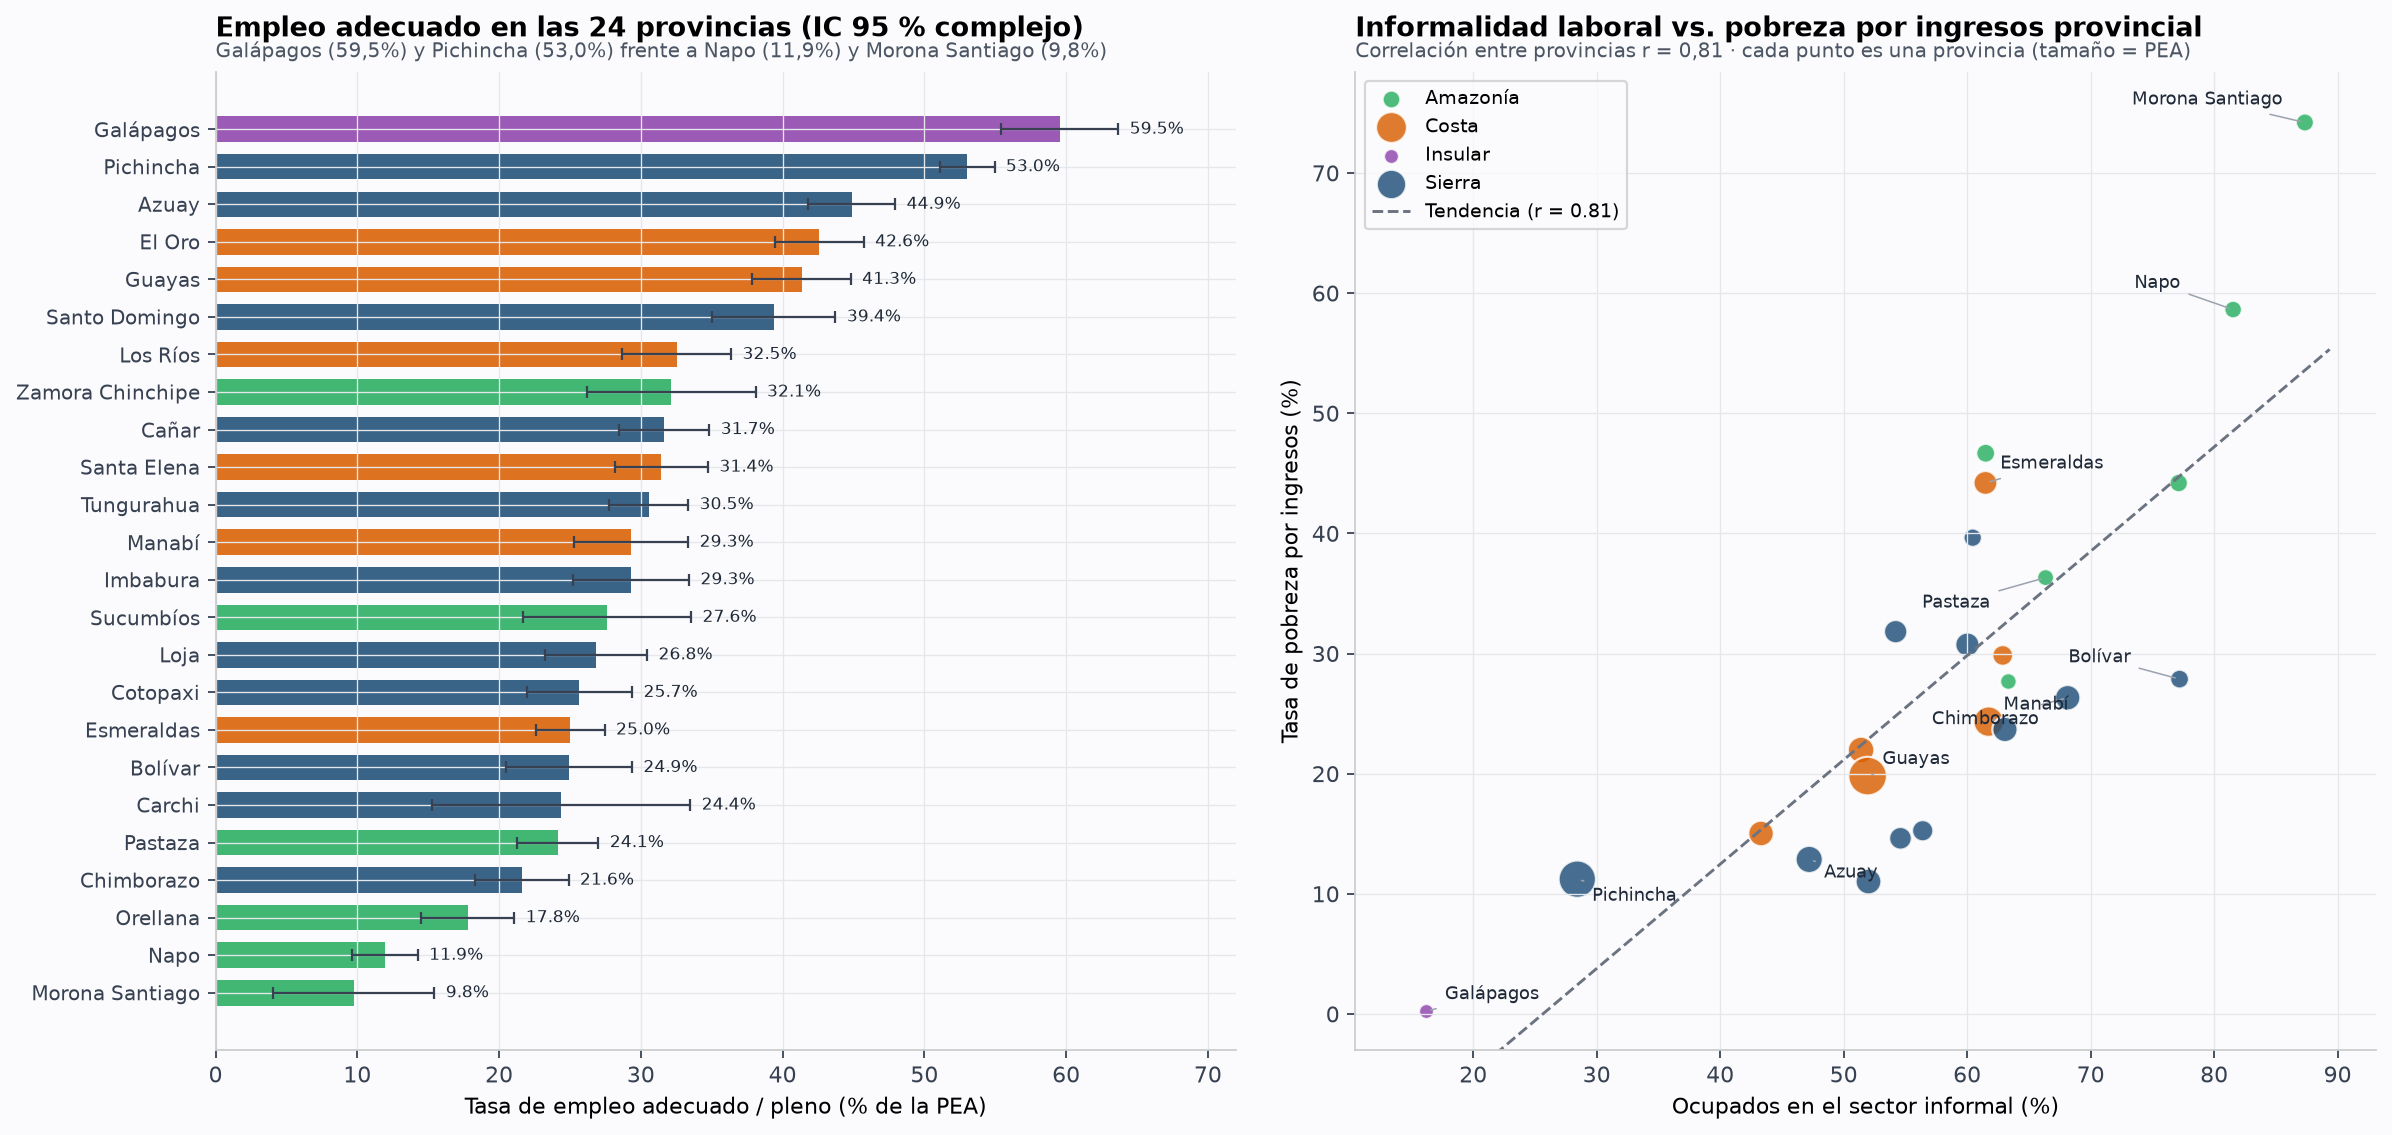

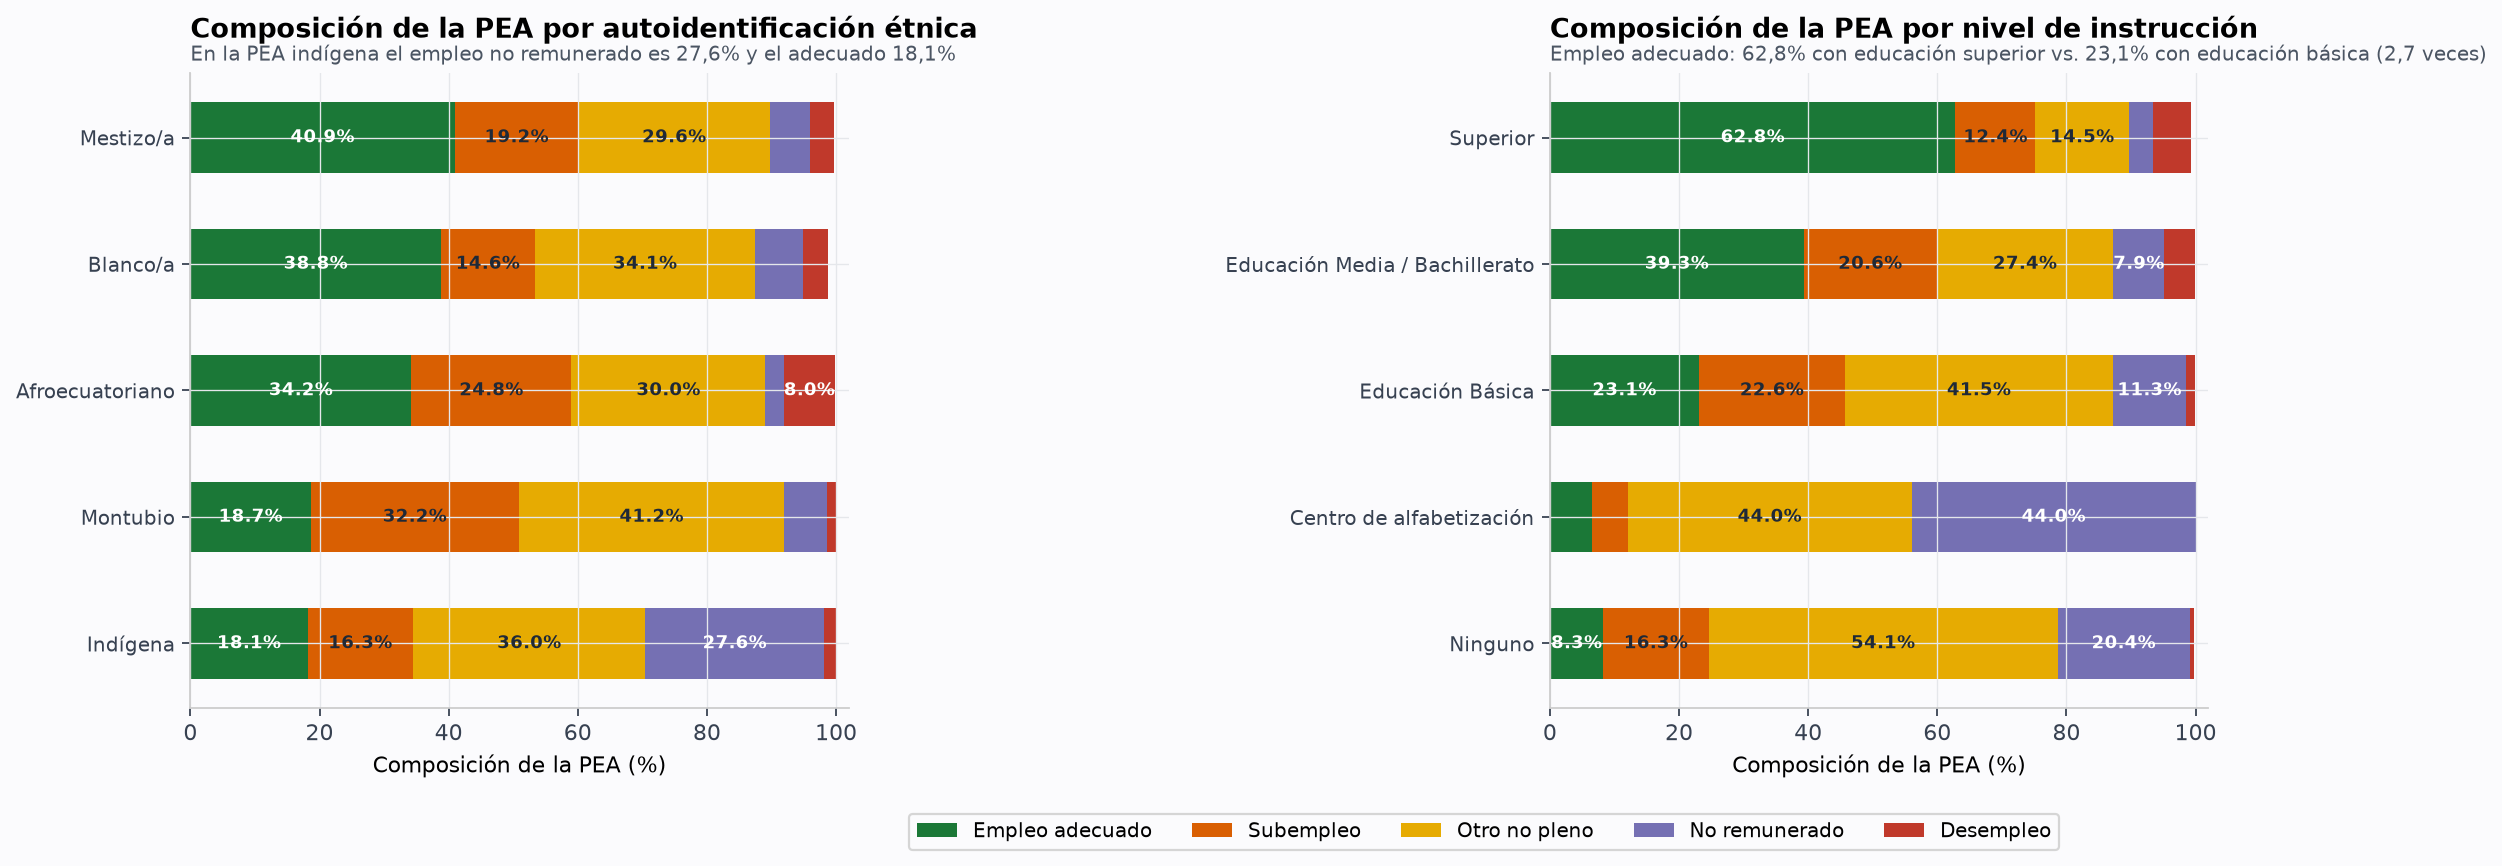

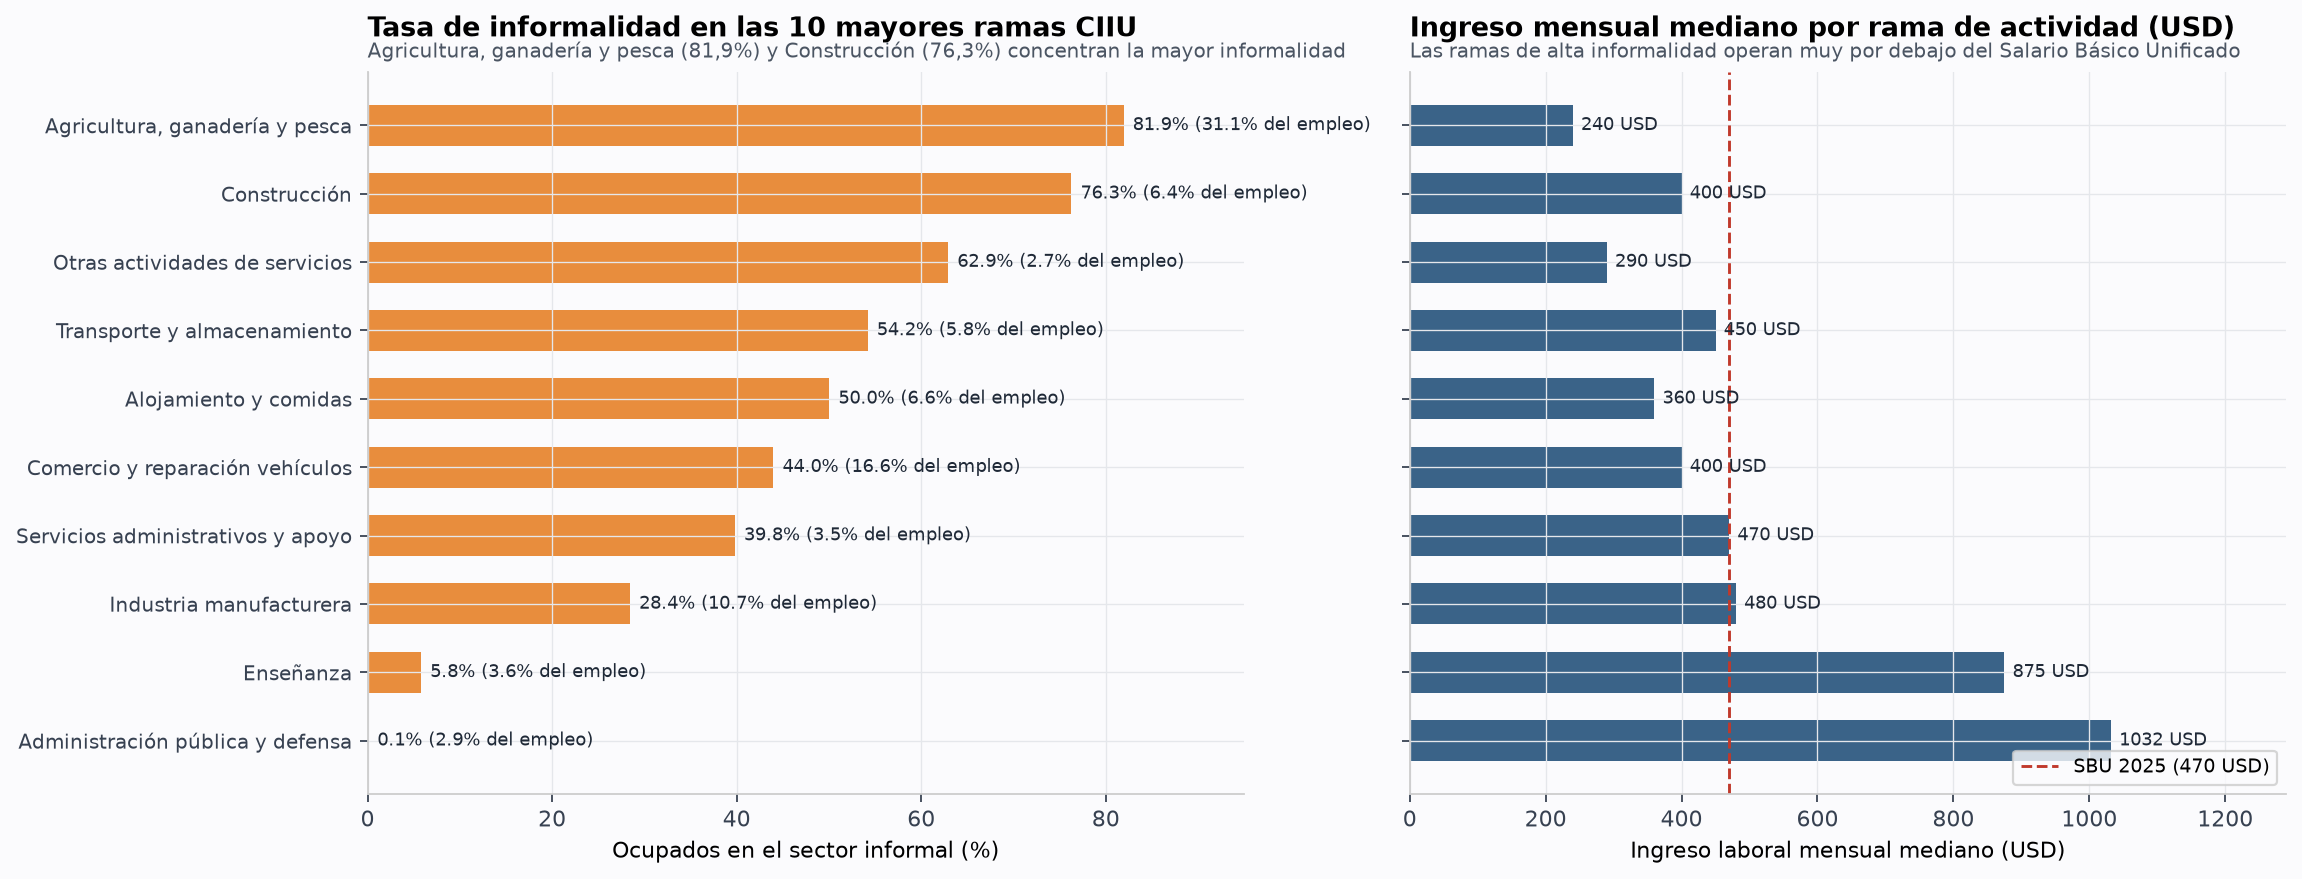

In [5]:
import tempfile
from pathlib import Path
from IPython.display import Image, display
from empleo_enemdu import graficos

# Las figuras se regeneran aquí desde los datos (en una carpeta temporal) y se muestran en línea
DIR_TMP = Path(tempfile.mkdtemp())
df_ramas = pd.read_csv(DIR_TABLAS / "indicadores_ramas_ciiu_2025.csv")

display(Image(filename=graficos.fig_02_evolucion_mercado_laboral_2018_2025(df_serie, DIR_TMP)))
display(Image(filename=graficos.fig_03_radiografia_provincial_informalidad_adecuado(df_prov, DIR_TMP)))
display(Image(filename=graficos.fig_04_brechas_demograficas_etnia_educacion(df_sub, DIR_TMP)))
display(Image(filename=graficos.fig_05_ramas_actividad_informalidad_ingresos(df_ramas, DIR_TMP)))